<a href="https://colab.research.google.com/github/divyachaudhary06/UCS420/blob/main/ASSIGNMENT_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024160083          # <-- your full roll number
NAME = "Divya Chaudhary"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160083   Name: Divya Chaudhary   Fingerprint: 502247F2   Tickets: 15

Ticket_ID                                                                                Ticket_Text
      T01                                       The password is running slowly. It worked yesterday.
      T02                                    The VPN keeps disconnecting. I don't know what changed.
      T03                        Password keeps disconnecting while uploading the file. Please help.
      T04                                                The state-of-the-art lab (Lab-3) is closed.
      T05                                                                Ticket #4521 is still open.
      T06          Laptop stopped responding after the latest update. The same problem occurs again.
      T07                                                                The file is 95.5% uploaded.
      T08                                          The LMS was working yesterday. Please resolve it.
    

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:

import pandas as pd

rows = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Number of sentences": len(result["sentences"]),
        "Number of tokens": len(result["tokens"]),
        "Number of punctuation tokens": len(result["punct"]),
        "Number of stopwords": len(result["stops"]),
        "Number of unique tokens": len(set(result["tokens"])),
        "Number of final tokens": len(result["final"])
    })

summary = pd.DataFrame(rows)

# Add totals for count-based columns
count_columns = [
    "Number of sentences",
    "Number of tokens",
    "Number of punctuation tokens",
    "Number of stopwords",
    "Number of final tokens"
]

total_row = {"Ticket_ID": "TOTAL"}

for column in count_columns:
    total_row[column] = summary[column].sum()

total_row["Number of unique tokens"] = "-"

summary = pd.concat(
    [summary, pd.DataFrame([total_row])],
    ignore_index=True
)

print("PREPROCESSING SUMMARY")
display(summary)

# Display token details for one selected ticket
selected_id = "T01"

selected_text = df.loc[
    df["Ticket_ID"] == selected_id, "Ticket_Text"
].iloc[0]

details = process_ticket(selected_text)

print("\nSelected Ticket:", selected_id)
print("Actual tokens:", details["tokens"])
print("Punctuation tokens:", details["punct"])
print("Stopwords:", details["stops"])
print("Final tokens:", details["final"])


PREPROCESSING SUMMARY


,Ticket_ID,Number of sentences,Number of tokens,Number of punctuation tokens,Number of stopwords,Number of unique tokens,Number of final tokens
0,T01,2,10,2,3,9,5
1,T02,2,12,2,4,11,6
2,T03,2,11,2,2,10,7
3,T04,1,9,3,2,9,4
4,T05,1,7,2,1,7,4
5,T06,2,14,2,5,12,7
6,T07,1,7,2,2,7,3
7,T08,2,10,2,3,9,5
8,T09,2,13,2,5,11,6
9,T10,1,11,1,4,9,6



Selected Ticket: T01
Actual tokens: ['the', 'password', 'is', 'running', 'slowly', '.', 'it', 'worked', 'yesterday', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['the', 'is', 'it']
Final tokens: ['password', 'running', 'slowly', 'worked', 'yesterday']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


import re

# Combine all ticket texts
raw_tickets = df["Ticket_Text"].tolist()
text = "\n".join(raw_tickets)

# 1. Extract words longer than 5 letters
long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)
print("1. Words longer than 5 letters:")
print(long_words)

# 2. Extract all numbers, keeping decimals and versions whole
numbers = re.findall(
    r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.])\d+(?:,\d{3})*(?![\w.])",
    text
)
print("\n2. Numbers:")
print(numbers)

# 3. Extract capitalized words
capitalized_words = re.findall(r"\b[A-Z][a-zA-Z]*\b", text)
print("\n3. Capitalized words:")
print(capitalized_words)

# 4. Extract words starting with a vowel
vowel_words = re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", text)
print("\n4. Words starting with a vowel:")
print(vowel_words)

# 5. Replace email addresses with <EMAIL>
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

# 6. Replace URLs with <URL>
url_pattern = r"https?://\S+|www\.\S+"

# 7. Replace phone numbers with <PHONE>
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[- ]?)?(?:\d[- ]?){8,14}\d(?!\w)"

cleaned_text = text
cleaned_text = re.sub(email_pattern, "<EMAIL>", cleaned_text)
cleaned_text = re.sub(url_pattern, "<URL>", cleaned_text)
cleaned_text = re.sub(phone_pattern, "<PHONE>", cleaned_text)

print("\n5. Text after replacing emails, URLs and phone numbers:")
print(cleaned_text)

# Test the patterns on the provided TEST_LINES
print("\n6. Testing replacement patterns on TEST_LINES:")

for line in TEST_LINES:
    result = re.sub(email_pattern, "<EMAIL>", line)
    result = re.sub(url_pattern, "<URL>", result)
    result = re.sub(phone_pattern, "<PHONE>", result)
    print(result)


1. Words longer than 5 letters:
['password', 'running', 'slowly', 'worked', 'yesterday', 'disconnecting', 'changed', 'Password', 'disconnecting', 'uploading', 'Please', 'closed', 'Ticket', 'Laptop', 'stopped', 'responding', 'latest', 'update', 'problem', 'occurs', 'uploaded', 'working', 'yesterday', 'Please', 'resolve', 'cannot', 'access', 'password', 'yesterday', 'worked', 'yesterday', 'change', 'anything', 'unable', 'resetting', 'password', 'Server', 'working', 'uploading', 'another', 'solution', 'Password', 'asking', 'connected', 'campus', 'changed', 'Laptop', 'failed', 'connected', 'campus', 'Please', 'asking', 'another', 'computer']

2. Numbers:
['3', '4521', '95.5']

3. Capitalized words:
['The', 'It', 'The', 'VPN', 'I', 'Password', 'Please', 'The', 'Lab', 'Ticket', 'Laptop', 'The', 'The', 'The', 'LMS', 'Please', 'I', 'It', 'I', 'I', 'I', 'WiFi', 'Can', 'Server', 'Is', 'Password', 'Wi', 'Fi', 'I', 'Laptop', 'Wi', 'Fi', 'Please', 'The', 'VPN', 'It']

4. Words starting with a vowel

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Capitalized words can include acronyms and product names, such as VPN, LMS, or MATLAB, as well as words capitalized at the start of a sentence. Run this optional cell to identify sentence-initial capitalized words whose lowercase forms also occur elsewhere in your data.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:

from nltk.tokenize import RegexpTokenizer, word_tokenize

# One regex pattern, with longer/special token types first
pattern = (
    r"https?://[^\s<>]+|www\.[^\s<>]+|"                  # URLs
    r"[\w.+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"             # Emails
    r"\+?\d[\d -]{7,}\d|"                                # Phone numbers
    r"\d+(?:\.\d+)+|"                                    # Decimals / versions
    r"[A-Za-z]+(?:['’][A-Za-z]+)+|"                      # Contractions
    r"[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+|"                   # Hyphenated terms
    r"[A-Za-z0-9_]+|"                                    # Ordinary words
    r"[^\w\s]"                                           # Punctuation
)

my_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

# Test on the supplied examples
print("CUSTOM TOKENIZER ON TEST_LINES")
for line in TEST_LINES:
    print(my_tokenize(line))

# Compare both tokenizers on every ticket
comparison = []

for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])

    comparison.append({
        "Ticket_ID": row["Ticket_ID"],
        "Custom token count": len(custom),
        "word_tokenize count": len(standard),
        "Different tokenization": custom != standard
    })

comparison_df = pd.DataFrame(comparison)

print("\nTOKENIZER COMPARISON")
display(comparison_df)

different_count = comparison_df["Different tokenization"].sum()
print("Tickets tokenized differently:", different_count)
print("Total tickets:", len(df))


CUSTOM TOKENIZER ON TEST_LINES
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']

TOKENIZER COMPARISON


,Ticket_ID,Custom token count,word_tokenize count,Different tokenization
0,T01,10,10,False
1,T02,11,12,True
2,T03,11,11,False
3,T04,9,9,False
4,T05,7,7,False
5,T06,14,14,False
6,T07,7,7,False
7,T08,10,10,False
8,T09,12,13,True
9,T10,9,11,True


Tickets tokenized differently: 4
Total tickets: 15


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The exact number depends on the generated dataset and the two tokenization rules. The final line of Cell 14 prints the number of tickets whose token lists differ.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:

import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()

# Custom suffix rule: remove common endings
custom_stemmer = RegexpStemmer(r"(ing|edly|ed|ly|s)$", min=3)

lemmatizer = WordNetLemmatizer()

# Collect unique final tokens using the official preprocessing function
unique_final_tokens = sorted({
    token
    for ticket in df["Ticket_Text"]
    for token in process_ticket(ticket)["final"]
})

# POS-tag the tokens
tagged_tokens = pos_tag(unique_final_tokens)

def wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"  # adjective
    elif tag.startswith("V"):
        return "v"  # verb
    elif tag.startswith("N"):
        return "n"  # noun
    elif tag.startswith("R"):
        return "r"  # adverb
    return "n"

rows = []

for word, tag in tagged_tokens:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = custom_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=wordnet_pos(tag))

    # Show only words whose methods do not all agree
    if len({p, l, r, lemma}) > 1:
        rows.append({
            "Word": word,
            "POS tag": tag,
            "Porter": p,
            "Lancaster": l,
            "Regexp stemmer": r,
            "WordNet lemma": lemma
        })

comparison_stems = pd.DataFrame(rows)

print("WORDS WITH DIFFERENT STEMMING / LEMMATIZATION RESULTS")
display(comparison_stems)
print("Number of differing words:", len(comparison_stems))


WORDS WITH DIFFERENT STEMMING / LEMMATIZATION RESULTS


,Word,POS tag,Porter,Lancaster,Regexp stemmer,WordNet lemma
0,access,NN,access,access,acces,access
1,another,DT,anoth,anoth,another,another
2,anything,NN,anyth,anyth,anyth,anything
3,campus,VB,campu,camp,campu,campus
4,change,NN,chang,chang,change,change
5,changed,VBN,chang,chang,chang,change
6,closed,VBD,close,clos,clos,close
7,computer,NN,comput,comput,computer,computer
8,file,NN,file,fil,file,file
9,latest,JJS,latest,latest,latest,late


Number of differing words: 29


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: A stemmer may remove too much of a word and produce a stem that no longer represents its intended meaning.



Under-stemming: A stemmer may leave related words with different stems even though they share a root.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Tokens,Unique tokens,TTR
0,S1 - All tokens,179,86,0.4804
1,S2 - No punctuation,149,80,0.5369
2,S3 - Final tokens,90,56,0.6222
3,S4 - Porter stems,90,52,0.5778



TOP 10 WORDS IN S1
     Word  Frequency
        .         24
      the         12
       is          6
        i          6
 password          5
       it          4
yesterday          4
    keeps          4
      n't          4
       to          4

TOP 10 WORDS IN S3
         Word  Frequency
     password          5
    yesterday          4
        keeps          4
          n't          4
         file          3
       please          3
        login          3
       worked          2
          vpn          2
disconnecting          2


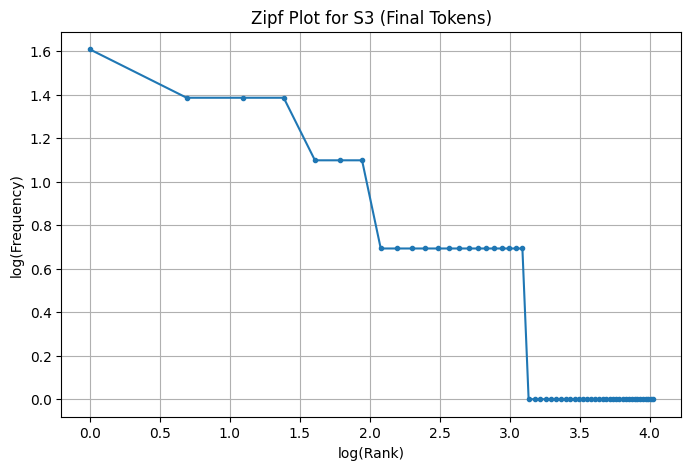


TOP 5 BIGRAMS IN S1
        Bigram  Frequency
      (., the)          6
        (., i)          5
(yesterday, .)          4
       (., it)          3
   (the, file)          3

TOP 5 BIGRAMS IN S3
                Bigram  Frequency
   (worked, yesterday)          2
          (vpn, keeps)          2
(keeps, disconnecting)          2
           (n't, know)          2
       (know, changed)          2


In [ ]:

from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
import pandas as pd
import matplotlib.pyplot as plt
import math

porter = PorterStemmer()

# Build four corpus versions from the official preprocessing pipeline
S1 = []
S2 = []
S3 = []

for ticket in df["Ticket_Text"]:
    result = process_ticket(ticket)

    S1.extend(result["tokens"])
    S2.extend(token for token in result["tokens"]
              if token not in result["punct"])
    S3.extend(result["final"])

S4 = [porter.stem(token) for token in S3]

# Corpus statistics
corpora = {
    "S1 - All tokens": S1,
    "S2 - No punctuation": S2,
    "S3 - Final tokens": S3,
    "S4 - Porter stems": S4
}

stats = []

for name, corpus in corpora.items():
    token_count = len(corpus)
    unique_count = len(set(corpus))
    ttr = unique_count / token_count if token_count else 0

    stats.append({
        "Corpus": name,
        "Tokens": token_count,
        "Unique tokens": unique_count,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)

print("CORPUS STATISTICS")
display(stats_df)

# Top 10 words in S1 and S3
print("\nTOP 10 WORDS IN S1")
print(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
).to_string(index=False))

print("\nTOP 10 WORDS IN S3")
print(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
).to_string(index=False))

# Zipf-style plot: log(rank) versus log(frequency) for S3
freq_sorted = Counter(S3).most_common()

if freq_sorted:
    ranks = list(range(1, len(freq_sorted) + 1))
    frequencies = [frequency for word, frequency in freq_sorted]

    log_ranks = [math.log(rank) for rank in ranks]
    log_frequencies = [math.log(freq) for freq in frequencies]

    plt.figure(figsize=(8, 5))
    plt.plot(log_ranks, log_frequencies, marker=".")
    plt.xlabel("log(Rank)")
    plt.ylabel("log(Frequency)")
    plt.title("Zipf Plot for S3 (Final Tokens)")
    plt.grid(True)
    plt.show()

# Top 5 bigrams in S1 and S3
print("\nTOP 5 BIGRAMS IN S1")
print(pd.DataFrame(
    Counter(bigrams(S1)).most_common(5),
    columns=["Bigram", "Frequency"]
).to_string(index=False))

print("\nTOP 5 BIGRAMS IN S3")
print(pd.DataFrame(
    Counter(bigrams(S3)).most_common(5),
    columns=["Bigram", "Frequency"]
).to_string(index=False))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* The type-token ratio (TTR) is the number of unique tokens divided by the total number of tokens. It changes from S1 to S4 because punctuation removal and stopword removal reduce the number of tokens, while Porter stemming can combine different word forms into the same stem. These changes affect both the total token count and the number of unique tokens, so TTR may increase or decrease depending on the corpus.